In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
#ДЗ
# 1. Для изображения sar_3.jpg найти наиболее протяженный участок
# (выделить линии при помощи преобразования Хафа)
# 2. Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

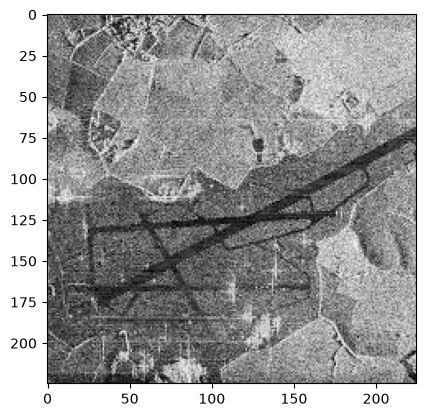

In [3]:
image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")
plt.show()

## Задание 2. Бинаризация

Сначала делаю бинаризацию, потому что она потом нужна для Хафа. Полосы на снимке темные, поэтому везде используется THRESH_BINARY_INV, чтобы полоса стала белой. Перед этим медианный фильтр, чтобы убрать спекл шум.

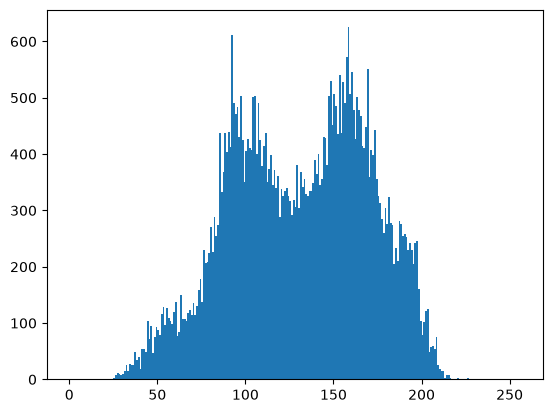

In [4]:
image_f = cv2.medianBlur(image_gray, 5)

plt.hist(image_f.ravel(), bins=256, range=(0, 256))
plt.show()

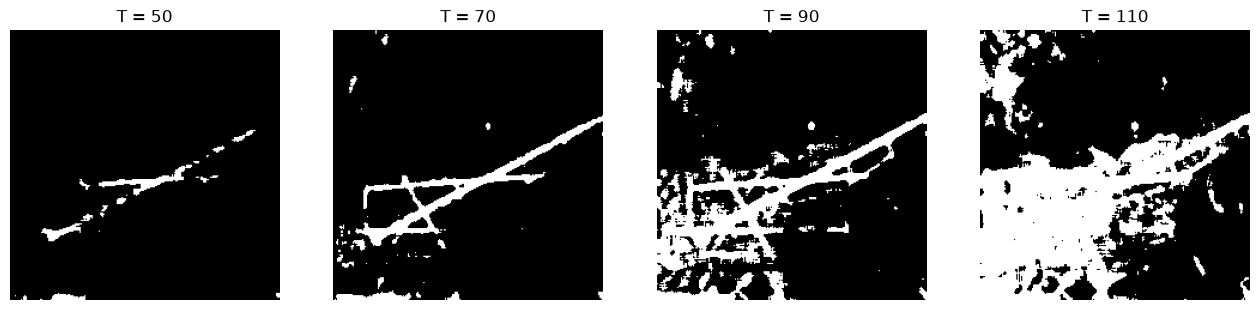

In [5]:
# точечная бинаризация с разными порогами
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for i, T in enumerate([50, 70, 90, 110]):
    _, b = cv2.threshold(image_f, T, 255, cv2.THRESH_BINARY_INV)
    ax[i].imshow(b, cmap="gray")
    ax[i].set_title('T = %d' % T)
    ax[i].axis('off')
plt.show()

In [6]:
T = 70
_, th_point = cv2.threshold(image_f, T, 255, cv2.THRESH_BINARY_INV)

T_otsu, th_otsu = cv2.threshold(image_f, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print('порог Отсу:', T_otsu)

th_adapt_mean = cv2.adaptiveThreshold(image_f, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 31, 20)
th_adapt_gauss = cv2.adaptiveThreshold(image_f, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 20)

порог Отсу: 128.0


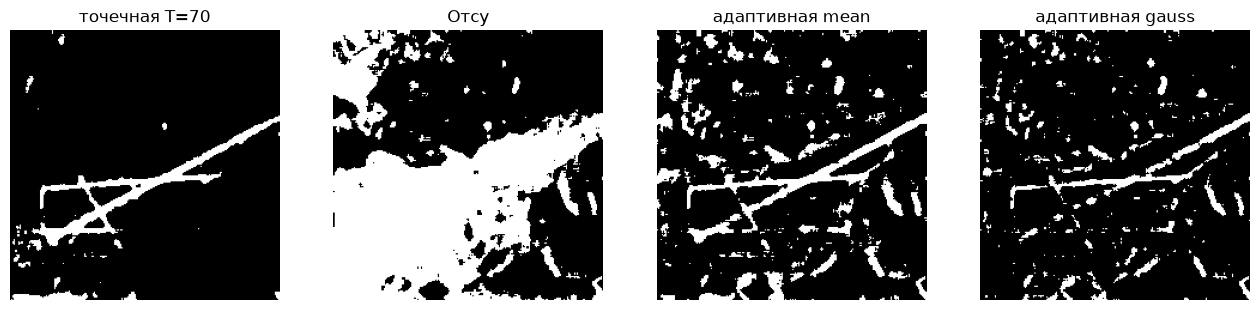

точечная T=70: белых пикселей 6.5%, компонент 41
Отсу: белых пикселей 46.8%, компонент 83
адаптивная mean: белых пикселей 14.1%, компонент 226
адаптивная gauss: белых пикселей 8.6%, компонент 259


In [7]:
names = ['точечная T=70', 'Отсу', 'адаптивная mean', 'адаптивная gauss']
bins = [th_point, th_otsu, th_adapt_mean, th_adapt_gauss]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
    ax[i].imshow(bins[i], cmap="gray")
    ax[i].set_title(names[i])
    ax[i].axis('off')
plt.show()

for name, b in zip(names, bins):
    n, _ = cv2.connectedComponents(b)
    print('%s: белых пикселей %.1f%%, компонент %d' % (name, 100 * np.count_nonzero(b) / b.size, n - 1))

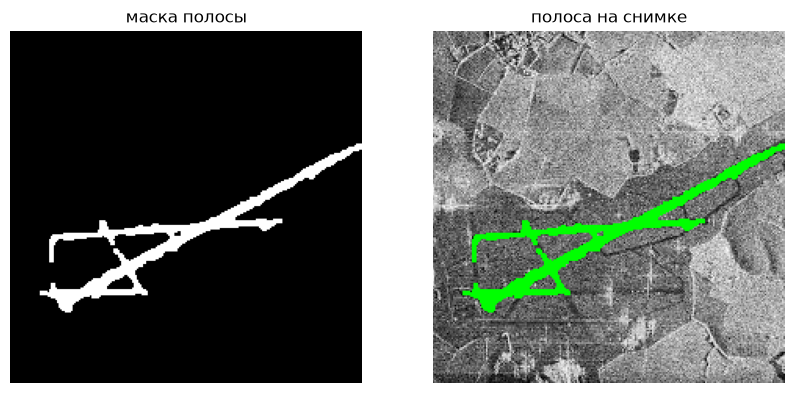

In [8]:
# выделение полосы: убираем мелкий шум и берем самую большую связную область
road = cv2.morphologyEx(th_point, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
n, labels, stats, _ = cv2.connectedComponentsWithStats(road)
k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
road = np.uint8(labels == k) * 255

road_img = image.copy()
road_img[road > 0] = (0, 255, 0)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(road, cmap="gray")
ax[0].set_title('маска полосы')
ax[1].imshow(cv2.cvtColor(road_img, cv2.COLOR_BGR2RGB))
ax[1].set_title('полоса на снимке')
for a in ax:
    a.axis('off')
plt.show()

## Задание 1. Преобразование Хафа

Если делать Canny прямо по снимку, то из-за шума Хаф находит много случайных линий по всему изображению. Поэтому границы ищу по маске полосы из задания 2.

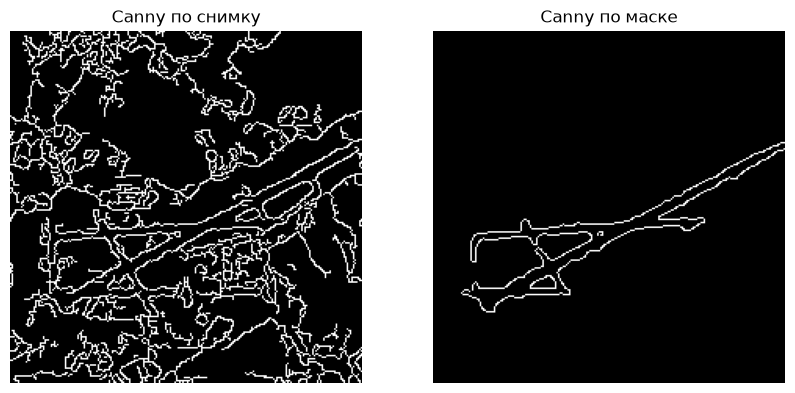

In [9]:
canny_raw = cv2.Canny(image_f, 50, 150)
canny = cv2.Canny(road, 50, 150)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(canny_raw, cmap="gray")
ax[0].set_title('Canny по снимку')
ax[1].imshow(canny, cmap="gray")
ax[1].set_title('Canny по маске')
for a in ax:
    a.axis('off')
plt.show()

In [10]:
lines = cv2.HoughLinesP(canny, 1, np.pi / 180, 30, minLineLength=40, maxLineGap=30)
lines = lines.reshape(-1, 4)
print('найдено отрезков:', len(lines))

lengths = np.hypot(lines[:, 2] - lines[:, 0], lines[:, 3] - lines[:, 1])
x1, y1, x2, y2 = lines[np.argmax(lengths)]
print('самый длинный: (%d, %d) - (%d, %d), длина %.1f px' % (x1, y1, x2, y2, lengths.max()))

найдено отрезков: 7
самый длинный: (28, 171) - (224, 71), длина 220.0 px


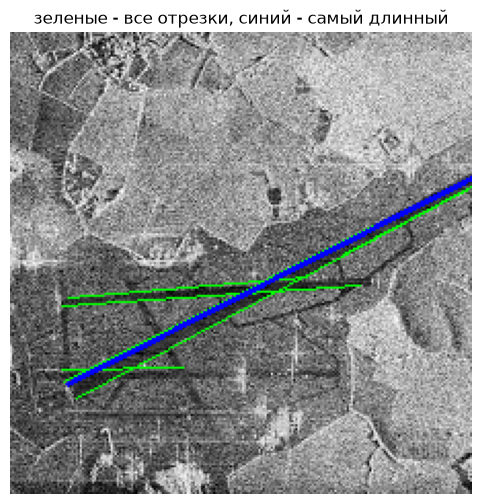

In [11]:
res = image.copy()
for l in lines:
    cv2.line(res, (l[0], l[1]), (l[2], l[3]), (0, 255, 0), 1)
cv2.line(res, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(res, cv2.COLOR_BGR2RGB))
plt.title('зеленые - все отрезки, синий - самый длинный')
plt.axis('off')
plt.show()

## Вывод

Метод Отсу на этом снимке не подходит: гистограмма почти одномодальная, порог получился 128 и в белое ушла почти половина изображения. Адаптивная бинаризация выделяет много мелких темных участков (больше 200 компонент), то есть реагирует на локальные перепады и шум. Лучше всего полосу выделила обычная точечная бинаризация с порогом 70, подобранным вручную, после нее остается мало лишнего и полосу легко отделить морфологией и выбором самой большой области.

Преобразование Хафа по маске полосы нашло 7 отрезков. Самый протяженный идет по основной взлетной полосе, длина около 220 px.